<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_28_Effective_Dimensionality_of_Hidden_Layers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import requests

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# Concept of Effective Dimensionality

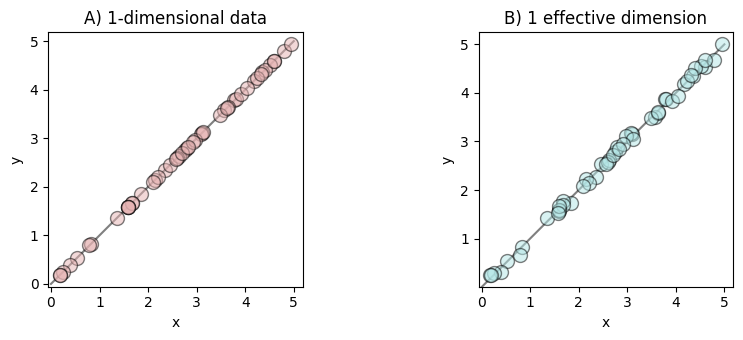

In [4]:
# a bit of data
x = np.random.uniform(low=0,high=5,size=50)
y = np.random.normal(loc=0,scale=.07,size=len(x))

_,axs = plt.subplots(1,2,figsize=(9,3.5))
axs[0].plot(x,x,'ko',markerfacecolor=[.9,.7,.7,.5],markersize=10)
axs[1].plot(x,x+y,'ko',markerfacecolor=[.7,.9,.9,.5],markersize=10)

for a in axs:
  a.axis('square')
  a.plot([0,5],[0,5],color='gray',zorder=-2)

axs[0].set(xlabel='x',ylabel='y',title='A) 1-dimensional data')
axs[1].set(xlabel='x',ylabel='y',title='B) 1 effective dimension')

plt.tight_layout()
plt.show()

# Part_1:Logits form real and shuffled token sequences

## Task_1:
- Import GPT-2-xl and its tokenizer. Toggle the model into eval
mode and move it to the GPU. Define a variable that encodes the
maximum context window size, which is the maximum number of
tokens the model can process at once. Hint: check model.config.
Import and tokenize the text for Through the Looking Glass
from gutenberg.org (see Chapter 2). Extract a max-token-sequence
length vector of tokens starting in the middle of the book. Print out
the tokens and enjoy reading a snippet of Alice’s adventures :)
Create a copy of the token sequence variable with randomly
shuffled tokens. Thus, you should now have two PyTorch tensors of
tokens to push through the model: One tensor is real tokens from
the text, and the other is the same tokens but in a randomly shuffled
order. Print those tokens.

In [3]:
tokenizer=AutoTokenizer.from_pretrained('gpt2')
model=AutoModelForCausalLM.from_pretrained('gpt2-xl')
model.eval()

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1600)
    (wpe): Embedding(1024, 1600)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-47): 48 x GPT2Block(
        (ln_1): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=4800, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=1600)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=6400, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=6400)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=1600, out_features=50257, bias=False)
)

In [ ]:
device=